In [ ]:
## import basic library

import laspy
import numpy as np
import matplotlib.pyplot as plt
import CSF
import open3d as o3d
import os

In [ ]:
# load pipeline corridor lidar file

las_path = "../data/processed_pipeline_corridor/40kmh_pipeline_corridor.las"

las = laspy.read(las_path)
print("Total points:", len(las.points))

Total points: 7307498


In [16]:
all_points = np.column_stack((
    np.array(las.x),
    np.array(las.y),
    np.array(las.z),
    #np.array(las.intensity),
    #np.array(las.return_number),
    #np.array(las.red),
    #np.array(las.green),
    #np.array(las.blue),
))

print(all_points.shape)

(7307498, 3)


In [17]:
points = all_points[:, 0:3]

print(points.shape)

(7307498, 3)


In [ ]:
# choose number of sample point for processing

sample_size = len(points)  #1000000

idx = np.random.choice(
    len(points),
    sample_size,
    replace=False
)

sample_points = points[idx]

print(sample_points.shape)

(1000000, 3)


In [ ]:
# apply csf

csf = CSF.CSF()


# Parameters
csf.params.bSloopSmooth = False
csf.params.cloth_resolution = 0.5
csf.params.class_threshold = 0.5
csf.params.interations = 500


csf.setPointCloud(sample_points)


ground = CSF.VecInt()
non_ground = CSF.VecInt()


csf.do_filtering(
    ground,
    non_ground
)


ground_idx = np.array(ground)
non_ground_idx = np.array(non_ground)


print("Ground:", len(ground_idx))
print("Non-ground:", len(non_ground_idx))

[0] Configuring terrain...
[0] Configuring cloth...
[0]  - width: 149 height: 303
[0] Rasterizing...
[0] Simulating...
Ground: 787684
Non-ground: 212316


In [20]:
ground_points = sample_points[ground_idx]

object_points = sample_points[non_ground_idx]

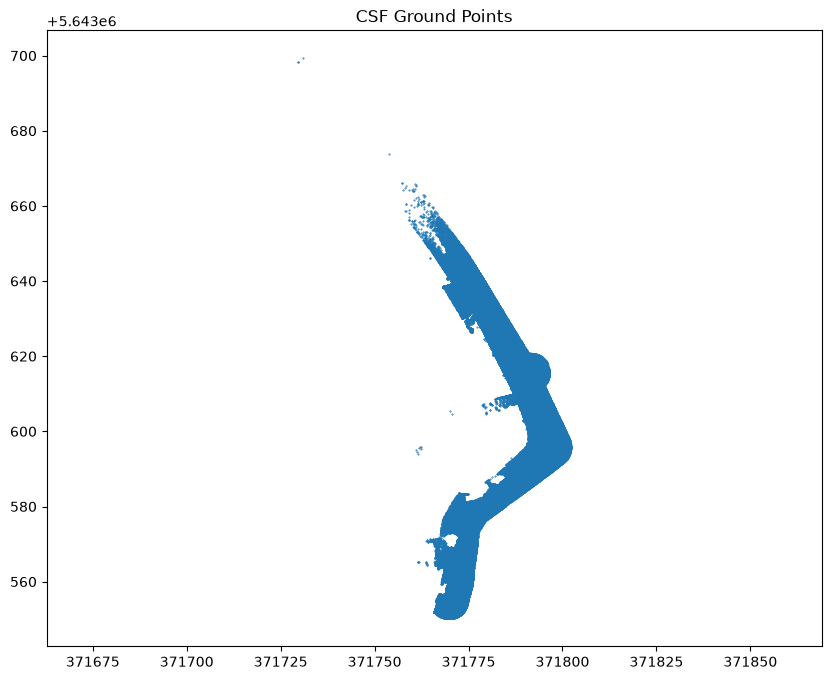

In [ ]:
# plot csf grounds points


plt.figure(figsize=(10,8))

plt.scatter(
    ground_points[:,0],
    ground_points[:,1],
    s=0.2
)

plt.axis("equal")
plt.title("CSF Ground Points")

plt.show()

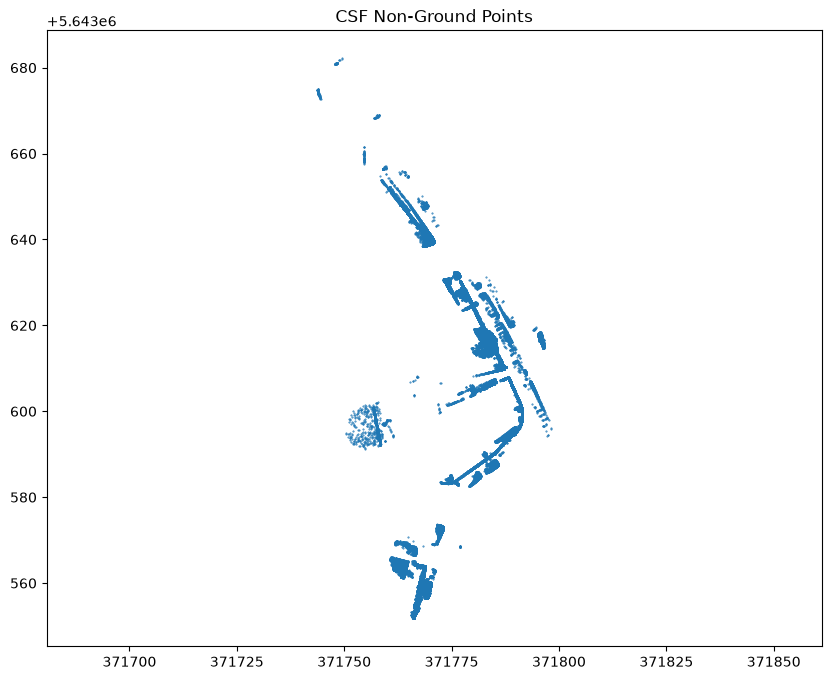

In [ ]:
# plot csf non grounds points

plt.figure(figsize=(10,8))

plt.scatter(
    object_points[:,0],
    object_points[:,1],
    s=0.2
)

plt.axis("equal")
plt.title("CSF Non-Ground Points")

plt.show()

In [ ]:
# apply sor

pcd = o3d.geometry.PointCloud()

pcd.points = o3d.utility.Vector3dVector(
    object_points
)


print("Before SOR:", len(pcd.points))


pcd_clean, ind = pcd.remove_statistical_outlier(
    nb_neighbors=20,
    std_ratio=2.0
)


print("After SOR:", len(pcd_clean.points))


clean_points = np.asarray(
    pcd_clean.points
)

Before SOR: 212316
After SOR: 207174


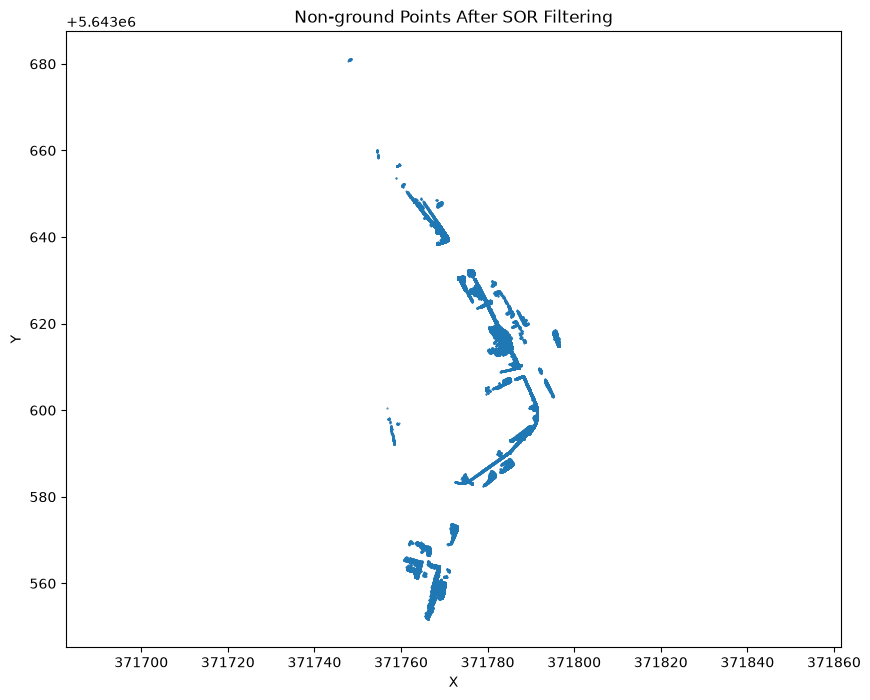

In [ ]:
# plot non ground points after sor

plt.figure(figsize=(10,8))

plt.scatter(
    clean_points[:,0],
    clean_points[:,1],
    s=0.2
)

plt.axis("equal")
plt.title("Non-ground Points After SOR Filtering")
plt.xlabel("X")
plt.ylabel("Y")

plt.show()

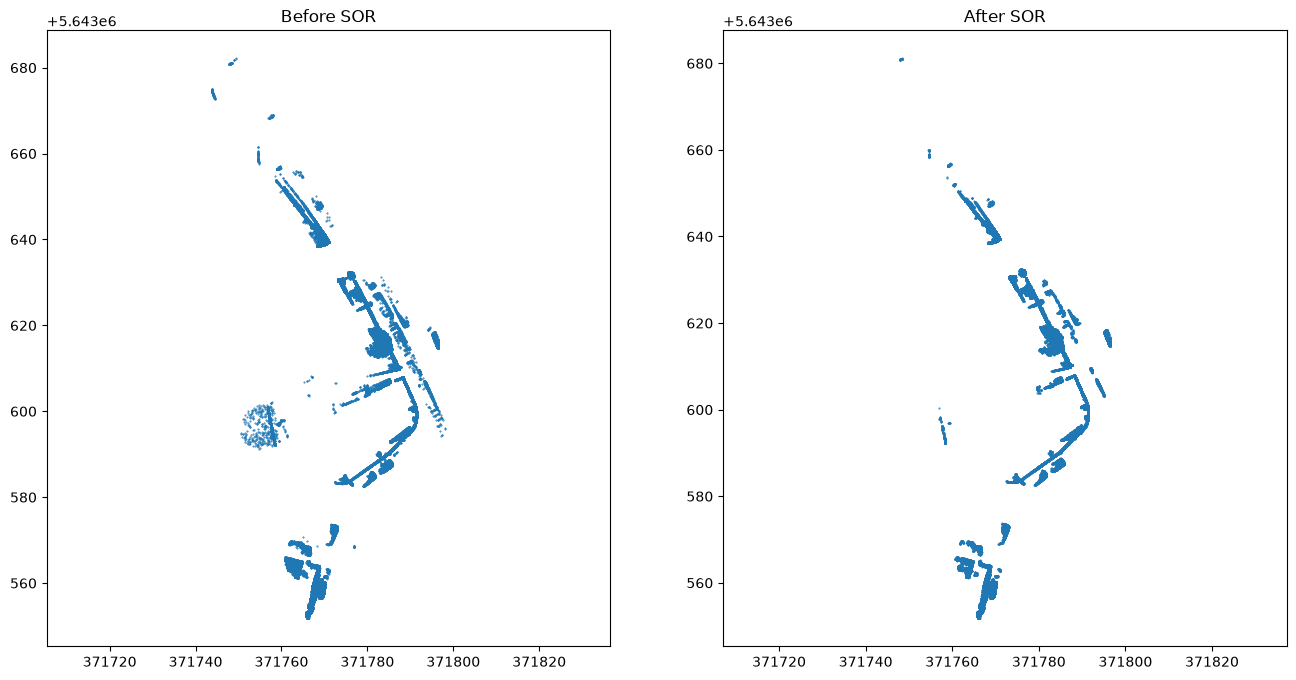

In [ ]:
# plot non ground points before sor vs after sor

fig, ax = plt.subplots(1, 2, figsize=(16,8))


# Before SOR
ax[0].scatter(
    object_points[:,0],
    object_points[:,1],
    s=0.2
)

ax[0].set_title(
    "Before SOR"
)

ax[0].axis("equal")


# After SOR
ax[1].scatter(
    clean_points[:,0],
    clean_points[:,1],
    s=0.2
)

ax[1].set_title(
    "After SOR"
)

ax[1].axis("equal")


plt.show()

In [ ]:
# save file after preprocessing

i = 40

input_path = f"../data/processed_pipeline_corridor/{i}kmh_pipeline_corridor.las"
output_path = f"../data/processed_non_ground_sor/{i}kmh_pipeline_corridor_nonground_sor.las"

# --- Read original header ---
with laspy.open(input_path) as src:
    header = src.header.copy()   
    las_full = src.read()   # read full data, all fields



# --- Apply that mask  xyz ---
clean_points = points[ind]     

# --- Create new LAS ---
new_las = laspy.LasData(header)
new_las.points = laspy.ScaleAwarePointRecord.zeros(len(clean_points), header=header)

new_las.x = clean_points[:, 0]
new_las.y = clean_points[:, 1]
new_las.z = clean_points[:, 2]
#new_las.intensity = clean_points[:, 3].astype(np.uint16)
#new_las.return_number = clean_points[:, 4].astype(np.uint8)
#new_las.red = clean_points[:, 5].astype(np.uint16)
#new_las.green = clean_points[:, 6].astype(np.uint16)
#new_las.blue = clean_points[:, 7].astype(np.uint16)

new_las.write(output_path)
print("Saved:", output_path)

Saved: ../data/processed_non_ground_sor/40kmh_pipeline_corridor_nonground_sor.las
